# 01 — Exploratory data analysis
MovieLens 25M and the Netflix Prize subsample (after the Stage 1 filtering). All numbers and figures come from `src/eda.py`; this notebook displays them. Re-run with `python -m src.eda`.

In [1]:
import json, pandas as pd
from pathlib import Path
from IPython.display import Image, Markdown, display
R = Path('..') / 'reports'
S = json.load(open(R/'eda_summary.json'))
def fig(n): display(Image(filename=str(R/'figures'/n)))

## 1. Size and sparsity

In [2]:
df = pd.DataFrame({k: S[k] for k in ['ml_25m','netflix']}).rename(columns={'ml_25m':'MovieLens 25M','netflix':'Netflix (50k users)'})
df.round(3)

,MovieLens 25M,Netflix (50k users)
users,1.622420e+05,4.981400e+04
items,1.317200e+04,1.003400e+04
ratings,2.463941e+07,1.150569e+07
density_pct,1.153000e+00,2.302000e+00
mean_rating,3.540000e+00,3.609000e+00
median_rating,4.000000e+00,4.000000e+00
ratings_per_user_median,7.100000e+01,1.200000e+02
ratings_per_user_mean,1.518680e+02,2.309730e+02
ratings_per_user_max,1.056900e+04,6.994000e+03
ratings_per_item_median,3.210000e+02,2.550000e+02


Both matrices are highly sparse (1.2% and 2.3% filled), so storing them densely is not an option; sparse CSR matrices are used throughout.

## 2. Rating distribution

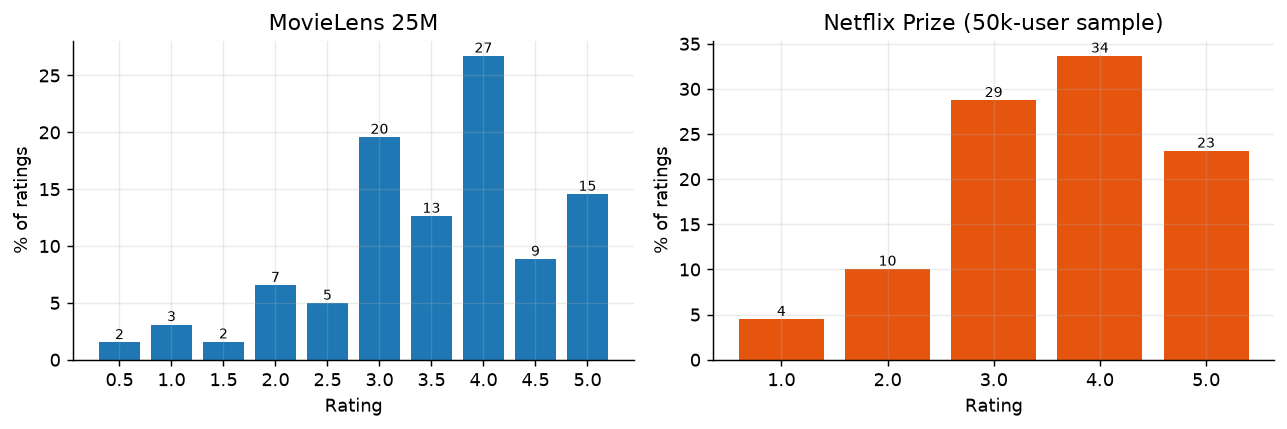

In [3]:
fig('eda_rating_distribution.png')

Ratings skew positive in both datasets (mean ≈ 3.5–3.6, median 4). A model that always predicts the mean already does reasonably well in RMSE, so the baselines matter.

## 3. User activity

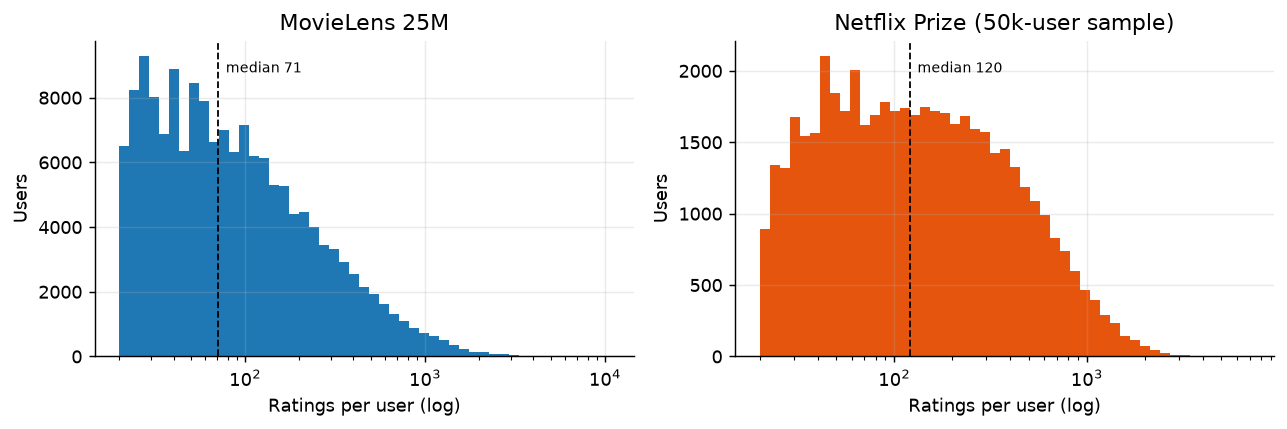

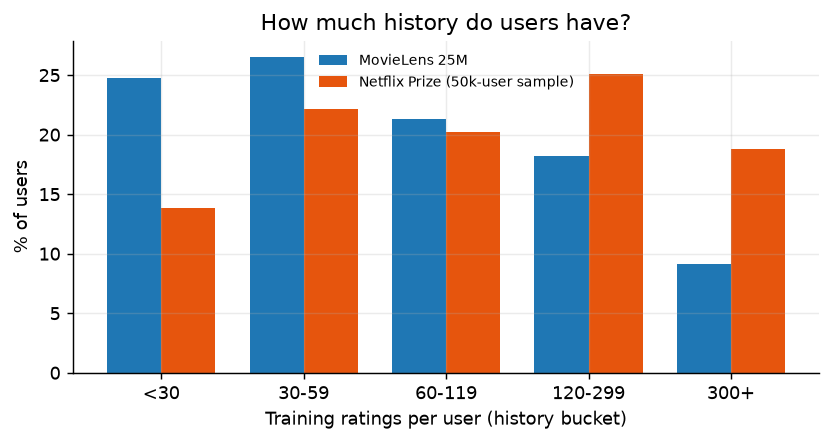

In [4]:
fig('eda_user_activity.png'); fig('eda_history_buckets.png')

Activity is heavy-tailed: the median user has 71 (MovieLens) / 120 (Netflix) ratings, but a few users have thousands. The history buckets are the ones used later for the low-history analysis.

## 4. Item popularity (long tail)

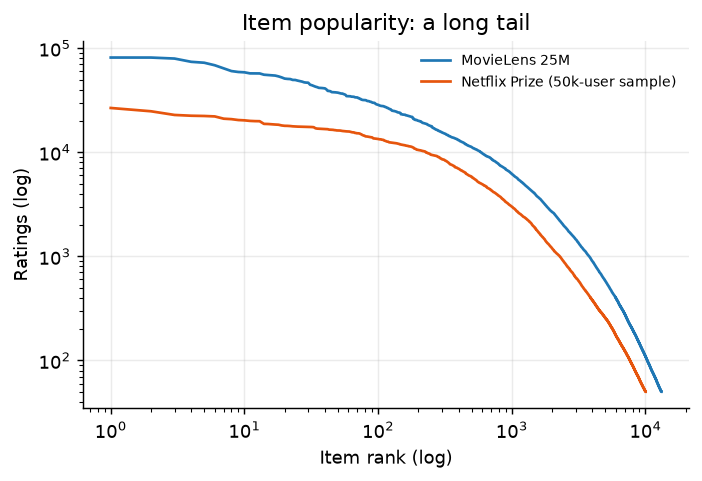

In [5]:
fig('eda_item_popularity.png')

The top 10% of items receive 68% (MovieLens) / 64% (Netflix) of all ratings. Popularity is therefore a strong non-personalized signal, which is why the popularity baseline is a meaningful bar for personalized models to clear.

## 5. Ratings over time

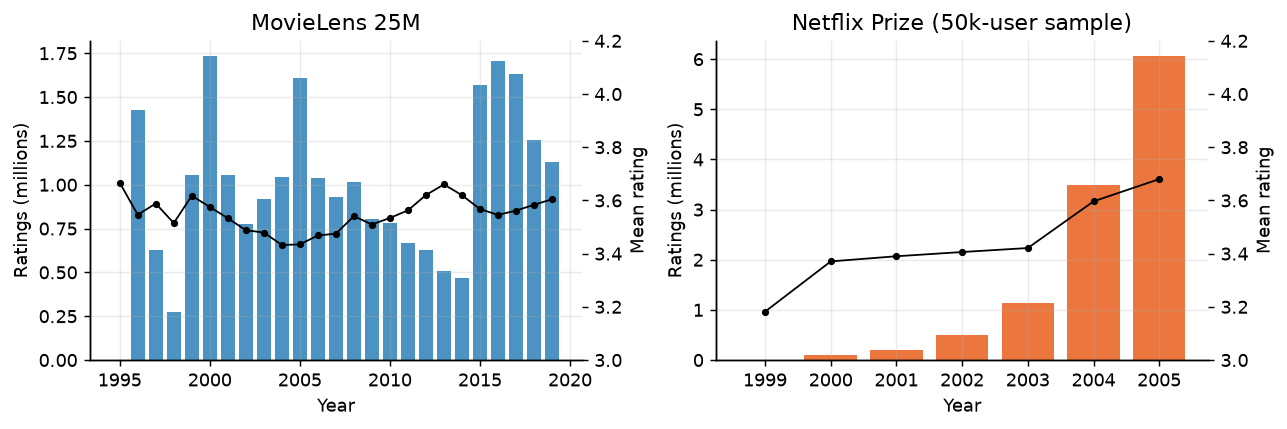

In [6]:
fig('eda_time.png')

Netflix Prize ratings are concentrated in 2004–2005 and drift upward; MovieLens spans 1995–2019. This is another reason results are compared within a dataset, not pooled.

## 6. Most rated and best rated movies

In [7]:
tables = Path('../reports/eda_tables.md').read_text()
display(Markdown(tables.split('## MovieLens 25M genres')[0]))

## Dataset statistics (after filtering, all splits)

|                              |   MovieLens 25M |   Netflix Prize (50k-user sample) |
|:-----------------------------|----------------:|----------------------------------:|
| users                        |     162,242.000 |                        49,814.000 |
| items                        |      13,172.000 |                        10,034.000 |
| ratings                      |  24,639,412.000 |                    11,505,691.000 |
| density_pct                  |           1.153 |                             2.302 |
| mean_rating                  |           3.540 |                             3.609 |
| median_rating                |           4.000 |                             4.000 |
| ratings_per_user_median      |          71.000 |                           120.000 |
| ratings_per_user_mean        |         151.868 |                           230.973 |
| ratings_per_user_max         |      10,569.000 |                         6,994.000 |
| ratings_per_item_median      |         321.000 |                           255.000 |
| ratings_per_item_max         |      81,450.000 |                        26,684.000 |
| share_ratings_top1pct_items  |           0.203 |                             0.145 |
| share_ratings_top10pct_items |           0.682 |                             0.635 |

## Most rated — MovieLens 25M

| title                                     |   ratings |   mean |
|:------------------------------------------|----------:|-------:|
| Forrest Gump (1994)                       |     81450 |  4.048 |
| Shawshank Redemption, The (1994)          |     81418 |  4.414 |
| Pulp Fiction (1994)                       |     79649 |  4.189 |
| Silence of the Lambs, The (1991)          |     74101 |  4.151 |
| Matrix, The (1999)                        |     72620 |  4.154 |
| Star Wars: Episode IV - A New Hope (1977) |     68670 |  4.12  |
| Jurassic Park (1993)                      |     64128 |  3.679 |
| Schindler's List (1993)                   |     60371 |  4.248 |
| Braveheart (1995)                         |     59171 |  4.002 |
| Fight Club (1999)                         |     58737 |  4.228 |

## Highest mean rating (≥1000 ratings) — MovieLens 25M

| title                                       |   ratings |   mean |
|:--------------------------------------------|----------:|-------:|
| Planet Earth II (2016)                      |      1123 |  4.484 |
| Planet Earth (2006)                         |      1747 |  4.465 |
| Shawshank Redemption, The (1994)            |     81418 |  4.414 |
| Band of Brothers (2001)                     |      1356 |  4.399 |
| Godfather, The (1972)                       |     52463 |  4.325 |
| Usual Suspects, The (1995)                  |     55344 |  4.285 |
| Godfather: Part II, The (1974)              |     34171 |  4.262 |
| Seven Samurai (Shichinin no samurai) (1954) |     13364 |  4.255 |
| Schindler's List (1993)                     |     60371 |  4.248 |
| 12 Angry Men (1957)                         |     16563 |  4.243 |

## Most rated — Netflix Prize (50k-user sample)

| title                                                         |   ratings |   mean |
|:--------------------------------------------------------------|----------:|-------:|
| Miss Congeniality (2000)                                      |     26684 |  3.35  |
| Independence Day (1996)                                       |     24802 |  3.734 |
| The Patriot (2000)                                            |     22867 |  3.784 |
| Pirates of the Caribbean: The Curse of the Black Pearl (2003) |     22475 |  4.155 |
| The Day After Tomorrow (2004)                                 |     22353 |  3.449 |
| Pretty Woman (1990)                                           |     22135 |  3.902 |
| Forrest Gump (1994)                                           |     21048 |  4.295 |
| The Green Mile (1999)                                         |     20836 |  4.302 |
| Con Air (1997)                                                |     20431 |  3.435 |
| Twister (1996)                                                |     20292 |  3.407 |

## Highest mean rating (≥2000 ratings) — Netflix Prize (50k-user sample)

| title                                                                      |   ratings |   mean |
|:---------------------------------------------------------------------------|----------:|-------:|
| Lord of the Rings: The Return of the King: Extended Edition (2003)         |      8569 |  4.726 |
| The Lord of the Rings: The Fellowship of the Ring: Extended Edition (2001) |      8566 |  4.713 |
| Lord of the Rings: The Two Towers: Extended Edition (2002)                 |      8728 |  4.698 |
| The Shawshank Redemption: Special Edition (1994)                           |     16192 |  4.588 |
| Star Wars: Episode V: The Empire Strikes Back (1980)                       |     10830 |  4.544 |
| Lord of the Rings: The Return of the King (2003)                           |     15686 |  4.54  |
| The Sopranos: Season 5 (2004)                                              |      2383 |  4.527 |
| Band of Brothers (2001)                                                    |      4423 |  4.521 |
| Star Wars: Episode IV: A New Hope (1977)                                   |      9965 |  4.51  |
| The Simpsons: Season 4 (1992)                                              |      2095 |  4.508 |



## 7. MovieLens genres

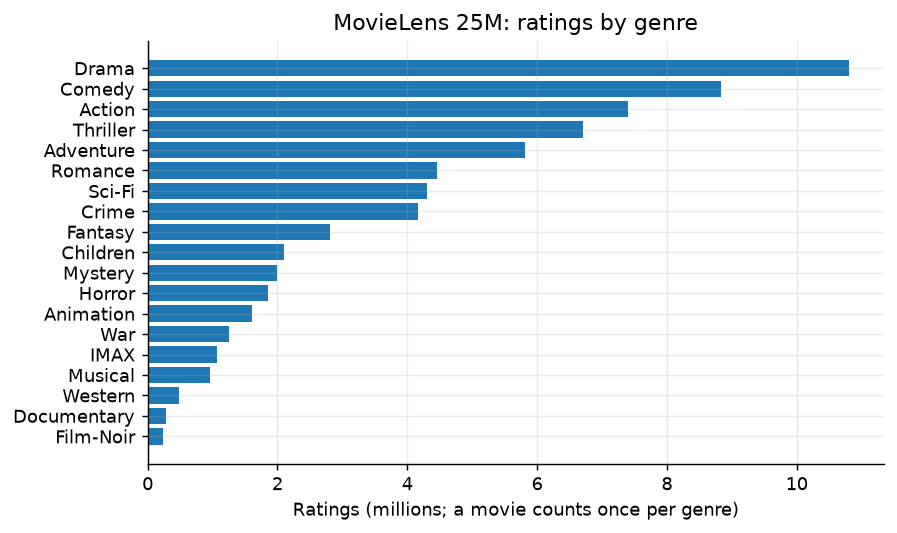

In [8]:
fig('eda_ml_genres.png')

## 8. Kaggle Netflix titles (metadata only)
This file has no user ratings, so it cannot be used for collaborative filtering (DIFFERENCE.md D2). It is useful for content features.

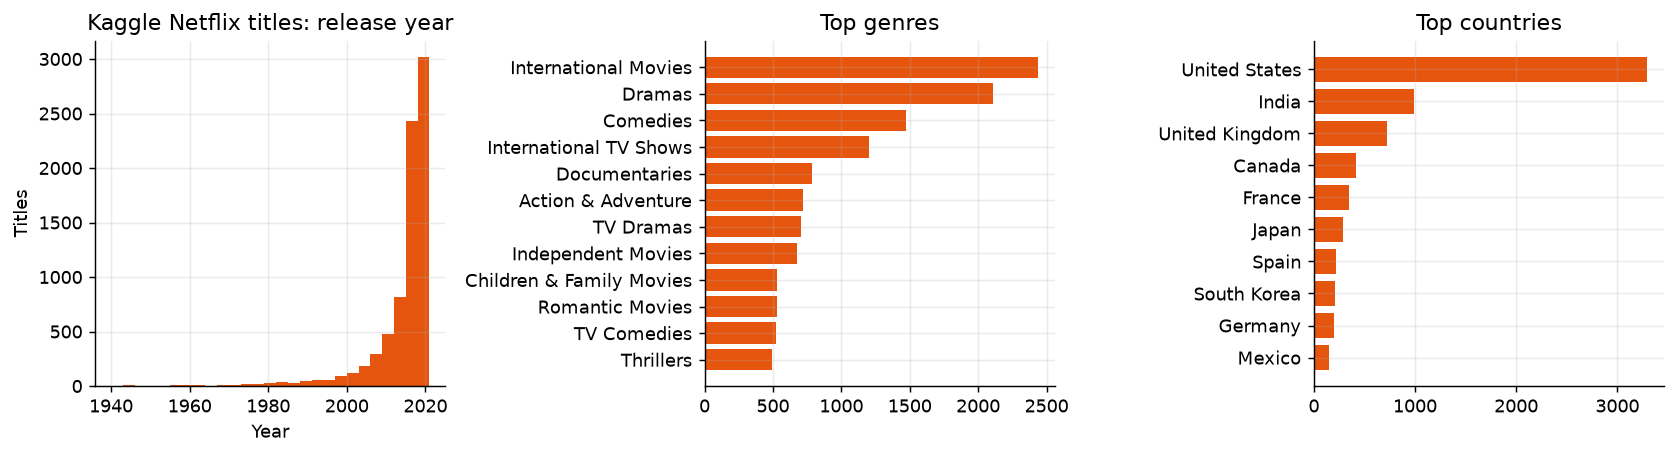

{'titles': 7787,
 'movies': 5377,
 'tv_shows': 2410,
 'missing_director_pct': 30.679337357133683,
 'missing_country_pct': 6.49800950301785,
 'release_year_min': 1925,
 'release_year_max': 2021}

In [9]:
fig('eda_kaggle_titles.png'); S['kaggle_netflix_titles']